
TRAINING ENSEMBLES

Training sparse ensemble...
Training dense ensemble...
Training extended ensemble...

EXPERIMENT 1
Epistemic vs Aleatoric @ 37°C
Rm: Epistemic σ = 6.469e-04, Aleatoric σ = 2.284e-03
Lm: Epistemic σ = 2.816e-11, Aleatoric σ = 1.548e-10
Cm: Epistemic σ = 6.310e-17, Aleatoric σ = 1.093e-16
Rs: Epistemic σ = 2.605e-11, Aleatoric σ = 1.846e-09


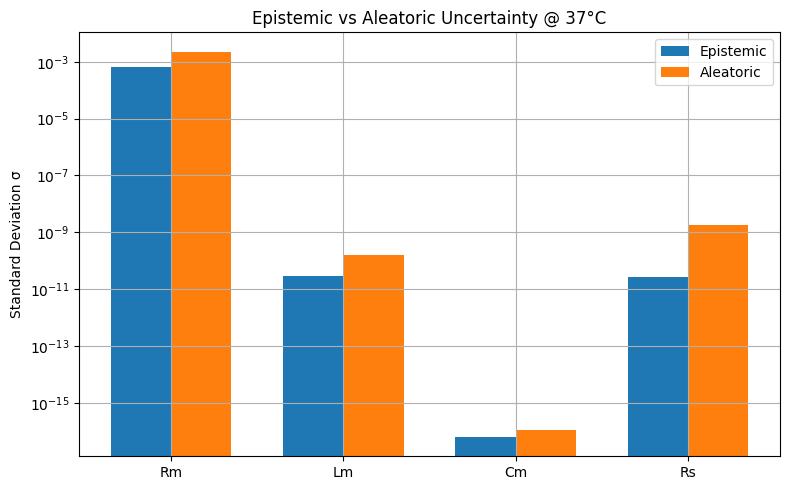


EXPERIMENT 2
Uncertainty vs Temperature


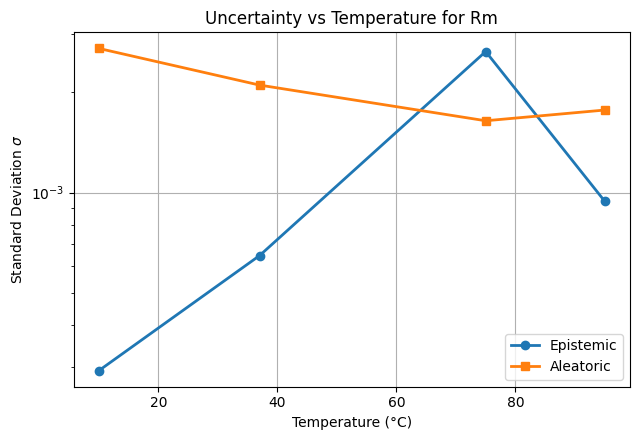

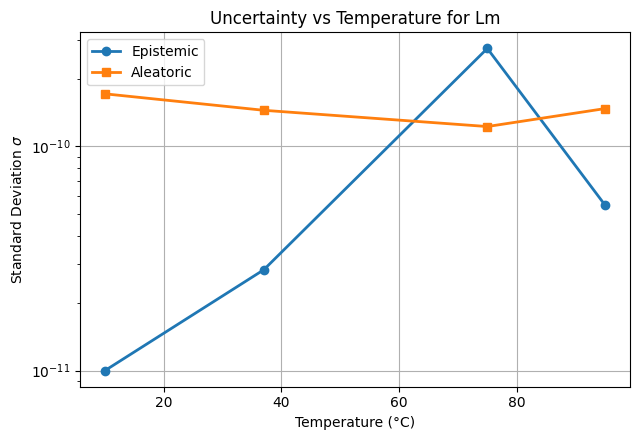

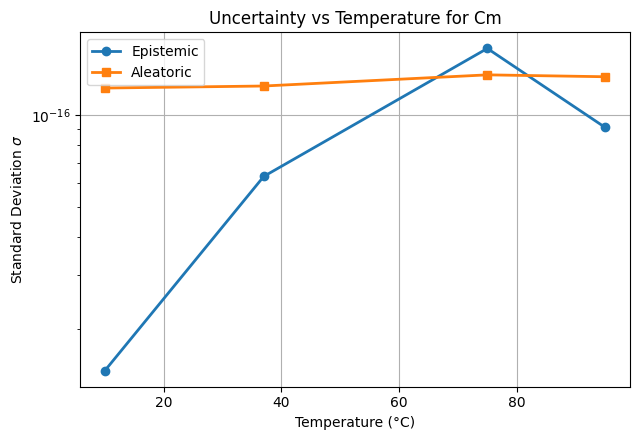

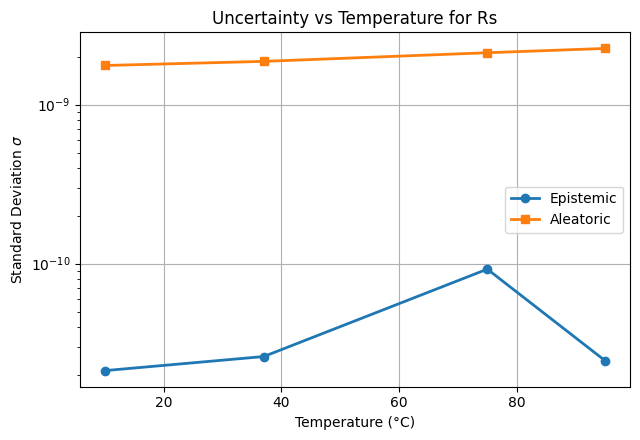


EXPERIMENT 3
Sparse vs Dense Calibration
Rm: Sparse=3.120e-03, Dense=2.903e-03
Lm: Sparse=1.216e-10, Dense=2.566e-10
Cm: Sparse=2.231e-16, Dense=2.674e-16
Rs: Sparse=9.712e-11, Dense=1.964e-10


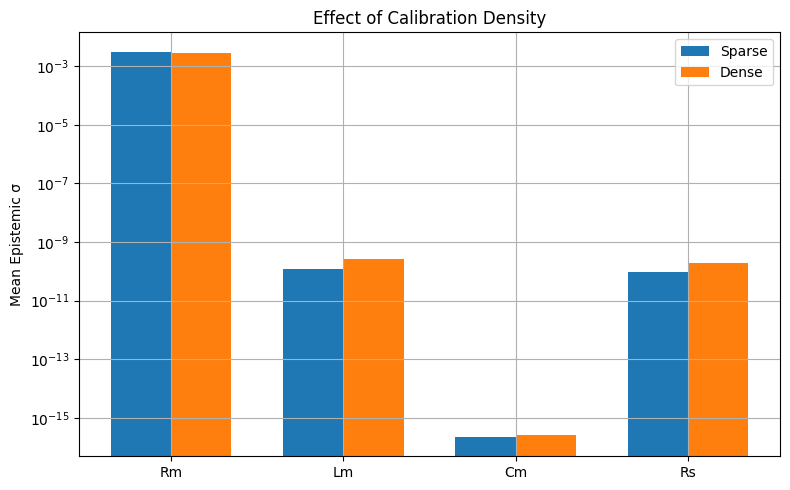


EXPERIMENT 4
Density vs Range
Rm: Sparse=3.120e-03, Dense=2.903e-03, Extended=1.930e-02
Lm: Sparse=1.216e-10, Dense=2.566e-10, Extended=9.870e-10
Cm: Sparse=2.231e-16, Dense=2.674e-16, Extended=1.021e-15
Rs: Sparse=9.712e-11, Dense=1.964e-10, Extended=4.513e-10


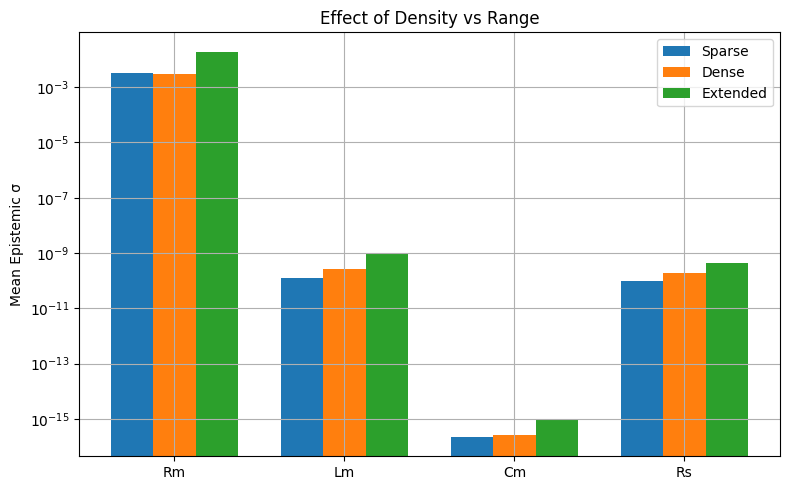


EXPERIMENT 5
Y11 Uncertainty Bands


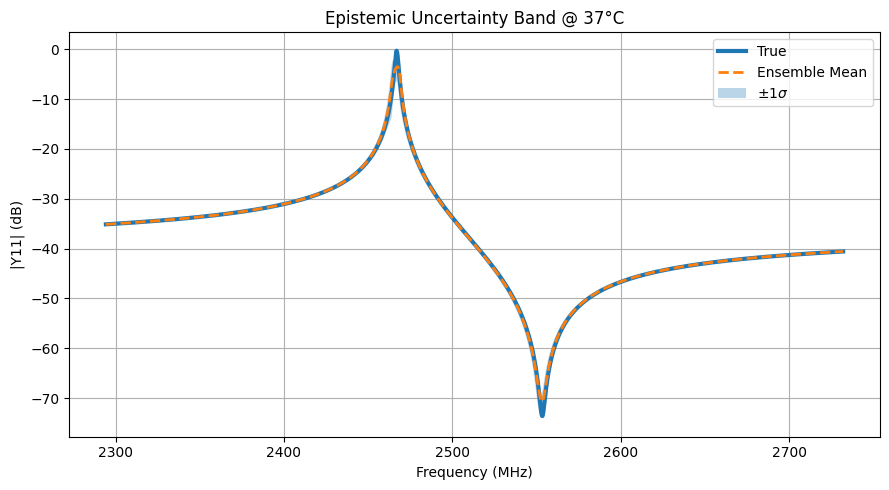


ALL EXPERIMENTS COMPLETED SUCCESSFULLY.


In [ ]:
# ================================================================
# FULLY CONSISTENT TEMPERATURE-DEPENDENT UNCERTAINTY FRAMEWORK
# ================================================================

import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import gc
import random
import math
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# ================================================================
# GLOBAL REPRODUCIBILITY
# ================================================================

SEED = 0

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)

np.random.seed(SEED)

tf.random.set_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except:
    pass

tf.get_logger().setLevel("ERROR")

# ================================================================
# CONSTANTS
# ================================================================

PI = math.pi

# ================================================================
# FIXED STRUCTURAL PARAMETERS
# ================================================================

Cs = 7.95e-13

R0 = 0.25

# ================================================================
# BASE PARAMETERS
# ================================================================

fr0 = 2.468e9

Qs0 = 887

Qp0 = 3770

k20 = 0.08

# ================================================================
# THERMAL MODEL PARAMETERS
# ================================================================

TCF1 = -35e-6
TCF2 = -4e-8
TCF3 = 2e-10

alpha1 = 5e-4
alpha2 = 2e-5

beta1 = 0.02
beta2 = 1e-4

gamma1 = 0.015
gamma2 = 8e-5

# ================================================================
# TRAINING SETTINGS
# ================================================================

N_ENSEMBLE = 5

EPOCHS = 1000

BATCH_SIZE = 16

# ================================================================
# TRUE NONLINEAR THERMAL MBVD MODEL
# ================================================================

def true_ECPs(T):

    dT = T - 25.0

    # ------------------------------------------------------------
    # RESONANCE FREQUENCY
    # ------------------------------------------------------------

    fr = fr0 * (

        1
        + TCF1*dT
        + TCF2*dT**2
        + TCF3*dT**3

    )

    # ------------------------------------------------------------
    # ELECTROMECHANICAL COUPLING
    # ------------------------------------------------------------

    k2 = k20 * (

        1
        + alpha1*dT
        + alpha2*dT**2

    )

    # ------------------------------------------------------------
    # SERIES QUALITY FACTOR
    # ------------------------------------------------------------

    Qs = Qs0 * np.exp(

        -beta1*dT/100
        + beta2*dT**2/10000

    )

    # ------------------------------------------------------------
    # PARALLEL QUALITY FACTOR
    # ------------------------------------------------------------

    Qp = Qp0 * np.exp(

        -gamma1*dT/100
        + gamma2*dT**2/10000

    )

    # ------------------------------------------------------------
    # ANTI-RESONANCE
    # ------------------------------------------------------------

    fa = (

        2*fr

        /

        (

            1
            +
            np.sqrt(
                1 - (16*k2)/(PI**2)
            )

        )

    )

    wr = 2*np.pi*fr

    wa = 2*np.pi*fa

    # ------------------------------------------------------------
    # MOTIONAL CAPACITANCE
    # ------------------------------------------------------------

    Cm = Cs * (

        (fa/fr)**2 - 1

    )

    # ------------------------------------------------------------
    # MOTIONAL INDUCTANCE
    # ------------------------------------------------------------

    Lm = 1 / (

        (2*np.pi*fr)**2 * Cm

    )

    # ------------------------------------------------------------
    # MOTIONAL RESISTANCE
    # ------------------------------------------------------------

    Rm = (

        wr * (Lm/Qs)

    ) - R0

    # ------------------------------------------------------------
    # STATIC BRANCH LOSS
    # ------------------------------------------------------------

    Rs = (

        wa * (Lm/Qp)

    ) - Rm

    return np.array([

        np.maximum(Rm,1e-6),

        np.maximum(Lm,1e-18),

        np.maximum(Cm,1e-18),

        np.maximum(Rs,1e-6)

    ])

# ================================================================
# STOCHASTIC EXTRACTION NOISE
# ================================================================

def noisy_ECPs(T):

    values = true_ECPs(T).copy()

    noise = np.random.uniform(0.001,0.003)

    for i in range(len(values)):

        values[i] *= (

            1 + noise*np.random.randn()

        )

    return values

# ================================================================
# BUILD ANN
# ================================================================

def build_model():

    tf.keras.backend.clear_session()

    model = tf.keras.Sequential([

        tf.keras.layers.Input(shape=(1,)),

        tf.keras.layers.Dense(
            64,
            activation="tanh",
            kernel_regularizer=tf.keras.regularizers.l2(1e-4)
        ),

        tf.keras.layers.Dense(
            64,
            activation="tanh",
            kernel_regularizer=tf.keras.regularizers.l2(1e-4)
        ),

        tf.keras.layers.Dense(
            32,
            activation="tanh",
            kernel_regularizer=tf.keras.regularizers.l2(1e-4)
        ),

        tf.keras.layers.Dense(4)

    ])

    model.compile(

        optimizer=tf.keras.optimizers.Adam(1e-3),

        loss="mse"

    )

    return model

# ================================================================
# TRAIN ENSEMBLE
# ================================================================

def train_ensemble(train_temps):

    X = []
    Y = []

    for T in train_temps:

        Rm,Lm,Cm,Rs = noisy_ECPs(T)

        X.append([T])

        Y.append([

            np.log(Rm),
            np.log(Lm),
            np.log(Cm),
            np.log(Rs)

        ])

    X = np.array(X,np.float32)

    Y = np.array(Y,np.float32)

    # ------------------------------------------------------------
    # NORMALIZATION
    # ------------------------------------------------------------

    Xm = X.mean(0)

    Xs = X.std(0)

    Ym = Y.mean(0)

    Ys = Y.std(0)

    Xs = np.maximum(Xs,1e-6)

    Ys = np.maximum(Ys,1e-6)

    Xn = (X-Xm)/Xs

    Yn = (Y-Ym)/Ys

    # ------------------------------------------------------------
    # TRAIN ENSEMBLE
    # ------------------------------------------------------------

    ensemble = []

    for i in range(N_ENSEMBLE):

        tf.keras.backend.clear_session()

        np.random.seed(i+1)

        tf.random.set_seed(i+1)

        model = build_model()

        earlystop = tf.keras.callbacks.EarlyStopping(

            monitor="loss",

            patience=50,

            restore_best_weights=True

        )

        model.fit(

            Xn,
            Yn,

            epochs=EPOCHS,

            batch_size=BATCH_SIZE,

            shuffle=False,

            verbose=0,

            callbacks=[earlystop]

        )

        ensemble.append(model)

    return ensemble, Xm, Xs, Ym, Ys

# ================================================================
# ENSEMBLE PREDICTION
# ================================================================

def ensemble_predict(

    ensemble,
    Xm,
    Xs,
    Ym,
    Ys,
    T

):

    Xt = (

        np.array([[T]],dtype=np.float32)

        - Xm

    ) / Xs

    preds = []

    for model in ensemble:

        yp = model.predict(

            Xt,
            verbose=0

        )[0]

        yp = yp*Ys + Ym

        yp = np.exp(yp)

        preds.append(yp)

    return np.array(preds)

# ================================================================
# EPISTEMIC UNCERTAINTY
# ================================================================

def epistemic_uncertainty(

    ensemble,
    Xm,
    Xs,
    Ym,
    Ys,
    T

):

    preds = ensemble_predict(

        ensemble,
        Xm,
        Xs,
        Ym,
        Ys,
        T

    )

    return preds.std(axis=0)

# ================================================================
# ALEATORIC UNCERTAINTY
# ================================================================

def aleatoric_uncertainty(T,n_samples=50):

    samples = []

    for _ in range(n_samples):

        samples.append(

            noisy_ECPs(T)

        )

    samples = np.array(samples)

    return samples.std(axis=0)

# ================================================================
# NONLINEAR MBVD RESPONSE
# ================================================================

def simulate_Y11(Rm,Lm,Cm,Rs,T):

    dT = T - 25.0

    # ------------------------------------------------------------
    # RECONSTRUCT fr
    # ------------------------------------------------------------

    fr = fr0 * (

        1
        + TCF1*dT
        + TCF2*dT**2
        + TCF3*dT**3

    )

    # ------------------------------------------------------------
    # RECONSTRUCT k2
    # ------------------------------------------------------------

    k2 = k20 * (

        1
        + alpha1*dT
        + alpha2*dT**2

    )

    # ------------------------------------------------------------
    # RECONSTRUCT fa
    # ------------------------------------------------------------

    fa = (

        2*fr

        /

        (

            1
            +
            np.sqrt(
                1 - (16*k2)/(PI**2)
            )

        )

    )

    # ------------------------------------------------------------
    # FREQUENCY SWEEP
    # ------------------------------------------------------------

    f = np.linspace(

        fr*0.93,
        fa*1.07,
        4000

    )

    w = 2*np.pi*f

    # ------------------------------------------------------------
    # STATIC BRANCH
    # ------------------------------------------------------------

    Zs = (

        R0
        +
        1/(1j*w*Cs)

    )

    # ------------------------------------------------------------
    # MOTIONAL BRANCH
    # ------------------------------------------------------------

    Zm = (

        Rm
        +
        1j*w*Lm
        +
        1/(1j*w*Cm)

    )

    # ------------------------------------------------------------
    # PARALLEL NETWORK
    # ------------------------------------------------------------

    Zp = 1/(1/Zs + 1/Zm)

    # ------------------------------------------------------------
    # TOTAL IMPEDANCE
    # ------------------------------------------------------------

    Ztotal = (

        Rs
        +
        Zp

    )

    # ------------------------------------------------------------
    # ADMITTANCE
    # ------------------------------------------------------------

    Y11 = np.abs(

        1/Ztotal

    )

    return f,Y11

# ================================================================
# TEMPERATURE SETTINGS
# ================================================================

train_sparse = [0,25,60,85,100]

train_dense = np.linspace(0,100,15)

train_extended = np.linspace(0,150,20)

temps_eval = [10,37,75,95]

temps_curve = np.linspace(0,150,60)

labels = ["Rm","Lm","Cm","Rs"]

# ================================================================
# TRAIN ENSEMBLES
# ================================================================

print("\n========================================")
print("TRAINING ENSEMBLES")
print("========================================")

print("\nTraining sparse ensemble...")

ens_sparse, Xm_s, Xs_s, Ym_s, Ys_s = train_ensemble(
    train_sparse
)

print("Training dense ensemble...")

ens_dense, Xm_d, Xs_d, Ym_d, Ys_d = train_ensemble(
    train_dense
)

print("Training extended ensemble...")

ens_ext, Xm_e, Xs_e, Ym_e, Ys_e = train_ensemble(
    train_extended
)

# ================================================================
# EXPERIMENT 1
# ================================================================

print("\n========================================")
print("EXPERIMENT 1")
print("Epistemic vs Aleatoric @ 37°C")
print("========================================")

epi_37 = epistemic_uncertainty(

    ens_sparse,
    Xm_s,
    Xs_s,
    Ym_s,
    Ys_s,
    37

)

ale_37 = aleatoric_uncertainty(37)

for i,label in enumerate(labels):

    print(
        f"{label}: "
        f"Epistemic σ = {epi_37[i]:.3e}, "
        f"Aleatoric σ = {ale_37[i]:.3e}"
    )

x = np.arange(len(labels))

width = 0.35

plt.figure(figsize=(8,5))

plt.bar(

    x-width/2,
    epi_37,
    width,
    label="Epistemic"

)

plt.bar(

    x+width/2,
    ale_37,
    width,
    label="Aleatoric"

)

plt.yscale("log")

plt.xticks(x,labels)

plt.ylabel("Standard Deviation σ")

plt.title(
    "Epistemic vs Aleatoric Uncertainty @ 37°C"
)

plt.grid(True)

plt.legend()

plt.tight_layout()

plt.show()

# ================================================================
# EXPERIMENT 2
# ================================================================

print("\n========================================")
print("EXPERIMENT 2")
print("Uncertainty vs Temperature")
print("========================================")

for p,label in enumerate(labels):

    epi_curve = []

    ale_curve = []

    for T in temps_eval:

        epi = epistemic_uncertainty(

            ens_sparse,
            Xm_s,
            Xs_s,
            Ym_s,
            Ys_s,
            T

        )

        ale = aleatoric_uncertainty(T)

        epi_curve.append(epi[p])

        ale_curve.append(ale[p])

    plt.figure(figsize=(6.5,4.5))

    plt.plot(

        temps_eval,
        epi_curve,

        marker='o',
        linewidth=2,

        label="Epistemic"

    )

    plt.plot(

        temps_eval,
        ale_curve,

        marker='s',
        linewidth=2,

        label="Aleatoric"

    )

    plt.yscale("log")

    plt.xlabel("Temperature (°C)")

    plt.ylabel(r"Standard Deviation $\sigma$")

    plt.title(
        f"Uncertainty vs Temperature for {label}"
    )

    plt.grid(True)

    plt.legend()

    plt.tight_layout()

    plt.show()

# ================================================================
# EXPERIMENT 3
# ================================================================

print("\n========================================")
print("EXPERIMENT 3")
print("Sparse vs Dense Calibration")
print("========================================")

mean_sparse = []

mean_dense = []

for T in temps_curve:

    s = epistemic_uncertainty(

        ens_sparse,
        Xm_s,
        Xs_s,
        Ym_s,
        Ys_s,
        T

    )

    d = epistemic_uncertainty(

        ens_dense,
        Xm_d,
        Xs_d,
        Ym_d,
        Ys_d,
        T

    )

    mean_sparse.append(s)

    mean_dense.append(d)

mean_sparse = np.array(mean_sparse)

mean_dense = np.array(mean_dense)

avg_sparse = mean_sparse.mean(axis=0)

avg_dense = mean_dense.mean(axis=0)

for i,label in enumerate(labels):

    print(
        f"{label}: "
        f"Sparse={avg_sparse[i]:.3e}, "
        f"Dense={avg_dense[i]:.3e}"
    )

plt.figure(figsize=(8,5))

plt.bar(

    x-width/2,
    avg_sparse,
    width,
    label="Sparse"

)

plt.bar(

    x+width/2,
    avg_dense,
    width,
    label="Dense"

)

plt.yscale("log")

plt.xticks(x,labels)

plt.ylabel("Mean Epistemic σ")

plt.title(
    "Effect of Calibration Density"
)

plt.grid(True)

plt.legend()

plt.tight_layout()

plt.show()

# ================================================================
# EXPERIMENT 4
# ================================================================

print("\n========================================")
print("EXPERIMENT 4")
print("Density vs Range")
print("========================================")

mean_ext = []

for T in temps_curve:

    e = epistemic_uncertainty(

        ens_ext,
        Xm_e,
        Xs_e,
        Ym_e,
        Ys_e,
        T

    )

    mean_ext.append(e)

mean_ext = np.array(mean_ext)

avg_ext = mean_ext.mean(axis=0)

for i,label in enumerate(labels):

    print(
        f"{label}: "
        f"Sparse={avg_sparse[i]:.3e}, "
        f"Dense={avg_dense[i]:.3e}, "
        f"Extended={avg_ext[i]:.3e}"
    )

w = 0.25

plt.figure(figsize=(8,5))

plt.bar(
    x-w,
    avg_sparse,
    w,
    label="Sparse"
)

plt.bar(
    x,
    avg_dense,
    w,
    label="Dense"
)

plt.bar(
    x+w,
    avg_ext,
    w,
    label="Extended"
)

plt.yscale("log")

plt.xticks(x,labels)

plt.ylabel("Mean Epistemic σ")

plt.title(
    "Effect of Density vs Range"
)

plt.grid(True)

plt.legend()

plt.tight_layout()

plt.show()

# ================================================================
# EXPERIMENT 5
# ================================================================

print("\n========================================")
print("EXPERIMENT 5")
print("Y11 Uncertainty Bands")
print("========================================")

T_example = 37

preds = ensemble_predict(

    ens_sparse,
    Xm_s,
    Xs_s,
    Ym_s,
    Ys_s,
    T_example

)

curves = []

for p in preds:

    Rm,Lm,Cm,Rs = p

    f,Y = simulate_Y11(

        Rm,
        Lm,
        Cm,
        Rs,
        T_example

    )

    curves.append(Y)

curves = np.array(curves)

Y_mean = curves.mean(axis=0)

Y_std = curves.std(axis=0)

Rm_t,Lm_t,Cm_t,Rs_t = true_ECPs(T_example)

_,Y_true = simulate_Y11(

    Rm_t,
    Lm_t,
    Cm_t,
    Rs_t,
    T_example

)

plt.figure(figsize=(9,5))

plt.plot(

    f/1e6,
    20*np.log10(Y_true),

    linewidth=3,

    label="True"

)

plt.plot(

    f/1e6,
    20*np.log10(Y_mean),

    "--",

    linewidth=2,

    label="Ensemble Mean"

)

upper = 20*np.log10(Y_mean + Y_std)

lower = 20*np.log10(
    np.maximum(Y_mean - Y_std,1e-15)
)

plt.fill_between(

    f/1e6,
    lower,
    upper,

    alpha=0.3,

    label=r"$\pm1\sigma$"

)

plt.xlabel("Frequency (MHz)")

plt.ylabel("|Y11| (dB)")

plt.title(
    "Epistemic Uncertainty Band @ 37°C"
)

plt.grid(True)

plt.legend()

plt.tight_layout()

plt.show()

print("\nALL EXPERIMENTS COMPLETED SUCCESSFULLY.")